In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
dataset = pd.read_csv("diabetes_prediction_dataset.csv")
dataset

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [5]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


In [7]:
dataset.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [8]:
dataset.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


Text(0.5, 1.0, 'Correletion heatmap')

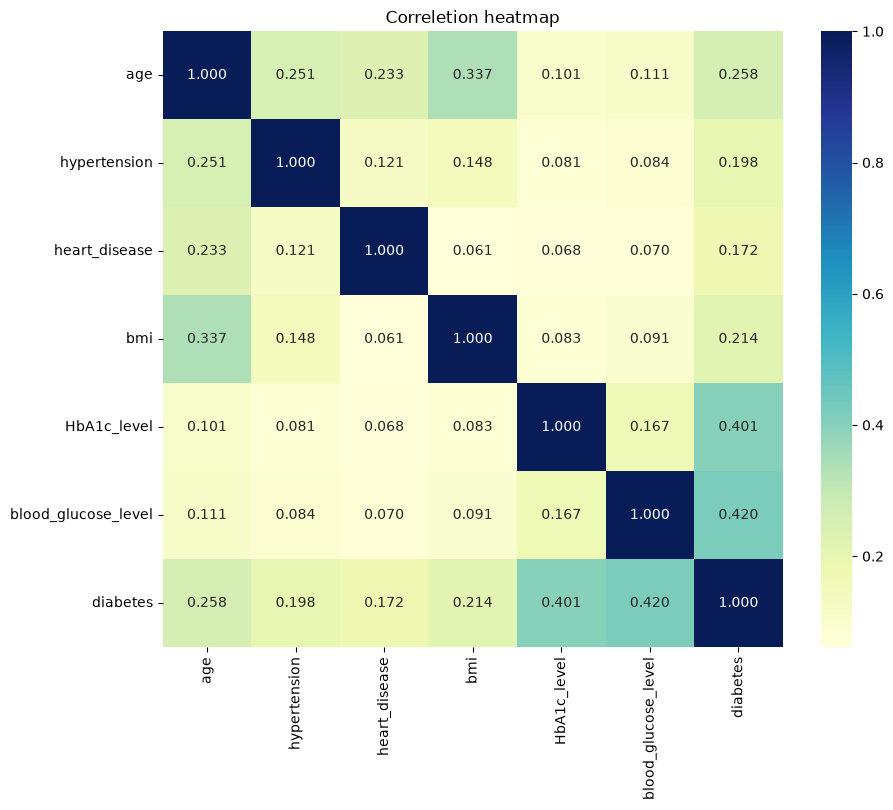

In [13]:
plt.figure(figsize =(10,8))
sns.heatmap(dataset.corr(numeric_only=True),annot = True,fmt=".3f",cmap ="YlGnBu")
plt.title("Correletion heatmap")

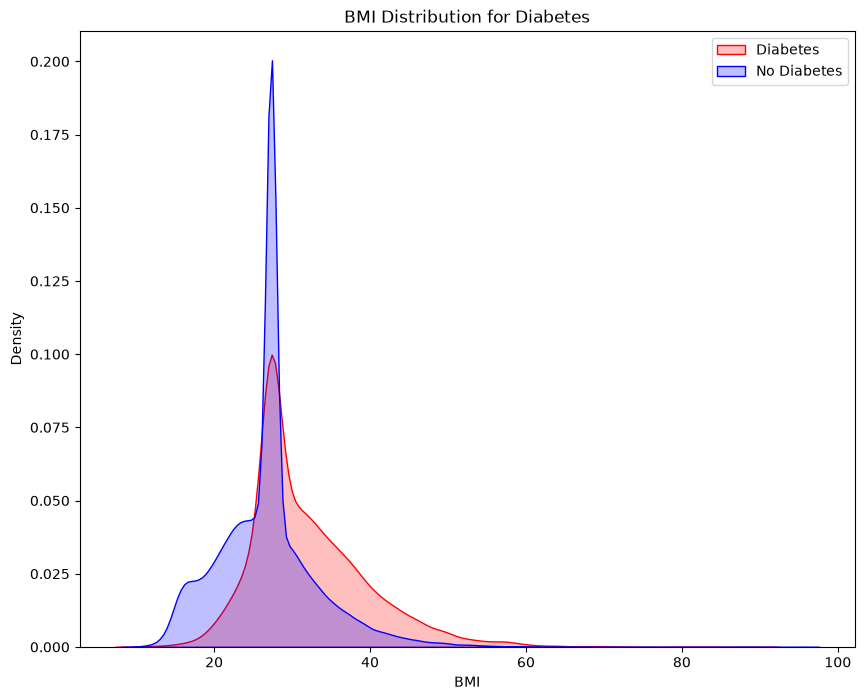

In [14]:
plt.figure(figsize =(10,8))
kde = sns.kdeplot(data=dataset[dataset["diabetes"]==1],x="bmi",color="red",fill=True)
kde = sns.kdeplot(data=dataset[dataset["diabetes"]==0],x="bmi",color="blue",fill=True)
plt.xlabel("BMI")
plt.ylabel("Density")
plt.legend(["Diabetes","No Diabetes"])
plt.title("BMI Distribution for Diabetes")
plt.show()

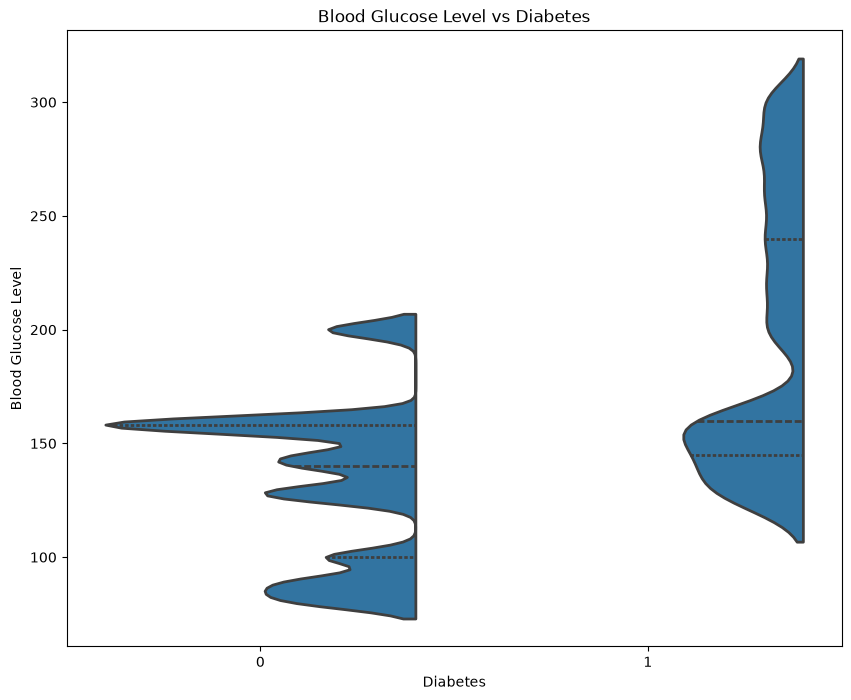

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,8))
sns.violinplot(data=dataset,x="diabetes",y="blood_glucose_level",split=True,linewidth=2,inner="quart")
plt.xlabel("Diabetes")
plt.ylabel("Blood Glucose Level")
plt.title("Blood Glucose Level vs Diabetes")
plt.show()

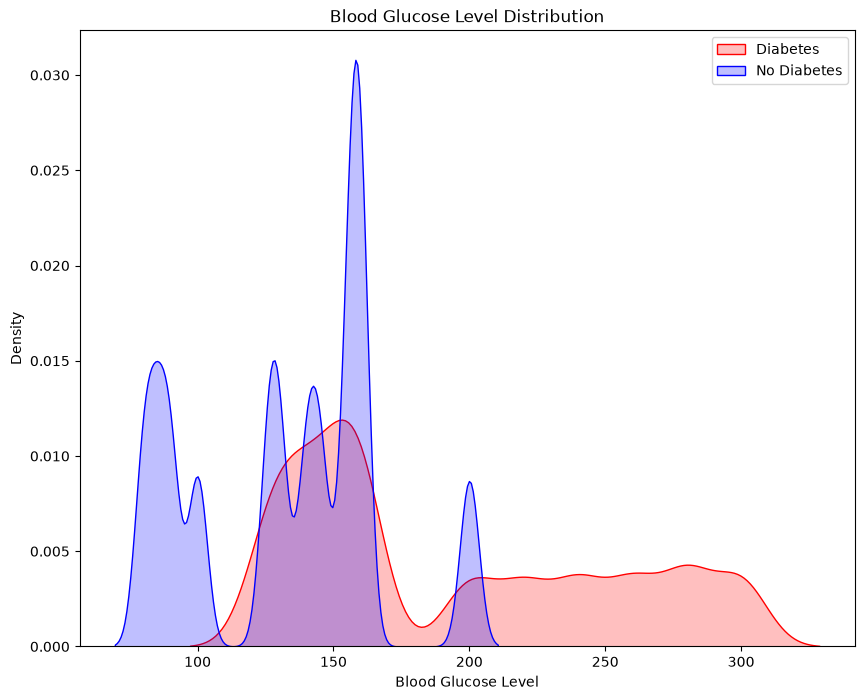

In [17]:
plt.figure(figsize=(10,8))

kde = sns.kdeplot(dataset["blood_glucose_level"][dataset["diabetes"] == 1],color="Red",fill=True)
kde = sns.kdeplot(dataset["blood_glucose_level"][dataset["diabetes"] == 0],color="Blue",fill=True)
plt.xlabel("Blood Glucose Level")
plt.ylabel("Density")
plt.legend(["Diabetes", "No Diabetes"])
plt.title("Blood Glucose Level Distribution")
plt.show()

In [22]:
dataset["bmi"] = dataset["bmi"].replace(0, dataset["bmi"].mean())
dataset["HbA1c_level"] = dataset["HbA1c_level"].replace(0, dataset["HbA1c_level"].median())
dataset["blood_glucose_level"] = dataset["blood_glucose_level"].replace(0, dataset["blood_glucose_level"].median())

In [23]:
dataset

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [33]:
X = dataset.drop("diabetes", axis=1)
y = dataset["diabetes"]

In [34]:
y

0        0
1        0
2        0
3        0
4        0
        ..
99995    0
99996    0
99997    0
99998    0
99999    0
Name: diabetes, Length: 100000, dtype: int64

In [36]:
from sklearn.preprocessing import LabelEncoder

le_gender = LabelEncoder()
le_smoking = LabelEncoder()

dataset["gender"] = le_gender.fit_transform(dataset["gender"])
dataset["smoking_history"] = le_smoking.fit_transform(dataset["smoking_history"])

In [37]:
X = dataset.drop("diabetes", axis=1)
y = dataset["diabetes"]

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [39]:
from sklearn.neighbors import KNeighborsClassifier

In [40]:
training_accuracy = []
test_accuracy = []

for n_neighbors in range(1, 11):
    knn = KNeighborsClassifier(n_neighbors=n_neighbors)
    knn.fit(X_train, y_train)

    training_accuracy.append(knn.score(X_train, y_train))
    test_accuracy.append(knn.score(X_test, y_test))

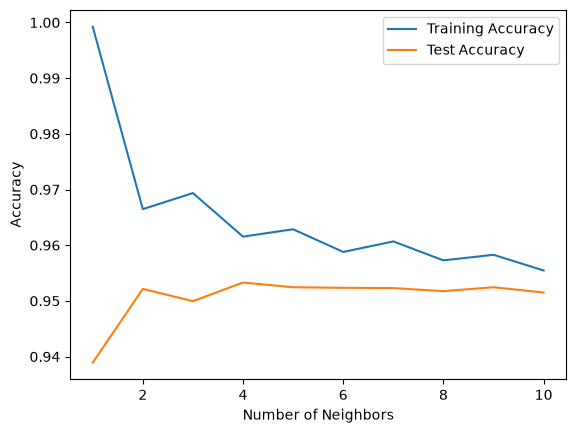

In [41]:
import matplotlib.pyplot as plt

plt.plot(range(1, 11), training_accuracy, label="Training Accuracy")
plt.plot(range(1, 11), test_accuracy, label="Test Accuracy")

plt.xlabel("Number of Neighbors")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [42]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=9)
knn.fit(X_train, y_train)

print("Training Accuracy:", knn.score(X_train, y_train))
print("Test Accuracy:", knn.score(X_test, y_test))

Training Accuracy: 0.958275
Test Accuracy: 0.95245


In [43]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=0)
dt.fit(X_train, y_train)

print("Training Accuracy:", dt.score(X_train, y_train))
print("Test Accuracy:", dt.score(X_test, y_test))

Training Accuracy: 0.9993125
Test Accuracy: 0.9531


In [44]:
dt1 = DecisionTreeClassifier(random_state=0, max_depth=3)
dt1.fit(X_train, y_train)

print("Training Accuracy:", dt1.score(X_train, y_train))
print("Test Accuracy:", dt1.score(X_test, y_test))

Training Accuracy: 0.9718
Test Accuracy: 0.97215


In [45]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(random_state=42)
mlp.fit(X_train, y_train)

print("Training Accuracy:", mlp.score(X_train, y_train))
print("Test Accuracy:", mlp.score(X_test, y_test))

Training Accuracy: 0.9659125
Test Accuracy: 0.9647


In [46]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)   # Use transform(), not fit_transform()

In [47]:
from sklearn.neural_network import MLPClassifier

mlp1 = MLPClassifier(random_state=0)

mlp1.fit(X_train_scaled, y_train)

print("Training Accuracy:", mlp1.score(X_train_scaled, y_train))
print("Test Accuracy:", mlp1.score(X_test_scaled, y_test))

Training Accuracy: 0.9722125
Test Accuracy: 0.9724
